# Forward modelling of gravity from the effective density

This notebook computes the gravity of a tapioca scenario in one instant with `harmonica.prism_gravity`, with the same approach as `gz_evolution.py`, which computes the whole evolution:

1. Effective density from `density.nc` and `temperature.nc`.
2. Top of the rock following `surface.nc` inside the cells.
3. Far field found in each scenario, or chosen by hand.
4. Density contrast relative to the far-field columns in the same time step, without mass above the sea level.
5. Water below the sea level, with Airy isostasy.
6. Flat observation level, 1 km above the highest surface of the whole simulation, with $g_z$ zero in the far field.

## 1. Data and settings

In [1]:
#increase the display size to 95% of window width
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
display(HTML("<style>.output_result { max-width:95% !important; }</style>"))


import os
import sys
import string
import harmonica as hm
import verde as vd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import subprocess
import multiprocessing #needed to run pymp in macOS
# multiprocessing.set_start_method('fork') #needed to run pymp in macOS arm architectures
import pymp

path = os.getcwd().split('/')
machine_path = '/'+path[1]+'/'+path[2] #cat the /home/user/ or /Users/user from system using path

sys.path.append(f"{machine_path}/opt/post_processing") #functions/mandyocIO.py, if the notebook is not run from post_processing
from functions.mandyocIO import (get_lithology_colors, plot_lithology_legend, find_far_field)

##File of fancy plot style. To use des.mplstyle file you must have an LaTeX distribution in your system
#plt.style.use(machine_path+'/Mestrado/cenarios/mandyoc/scripts_gera_inputs_imgs/new_outputs/des.mplstyle')

In [2]:
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_dz05_Clc10_Cmlit025_Ts0_1080'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc10_Cmlit025_Ts0_1080'

# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1080'
model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1090'
# model_path = '/Volumes/Joao_Macedo/tests_rft/Ho35S1_Clc40_Cmlit025_Ts0_1100'

rho0 = xr.open_dataset(f"{model_path}/density.nc", cache=False, engine="h5netcdf")["density"]
T0 = xr.open_dataset(f"{model_path}/temperature.nc", cache=False, engine="h5netcdf")["temperature"]
surface = xr.open_dataset(f"{model_path}/surface.nc", cache=False, engine="h5netcdf")["surface"]
lithology = xr.open_dataset(f"{model_path}/lithology.nc", cache=False, engine="h5netcdf")["lithology"]
strain = xr.open_dataset(f"{model_path}/strain.nc", cache=False, engine="h5netcdf")["strain"]

x = rho0.x.values.astype(float)
z = rho0.z.values.astype(float)
Nx = x.size
Nz = z.size
Lx = x[-1]
Lz = z[0]
dz = z[1] - z[0]
dx = x[1] - x[0]
z_bottom = z - dz/2
z_top = z + dz/2
X, Z = np.meshgrid(x, z)

alpha = 3.28e-5 #thermal expansion coefficient

rho_eff = rho0*(1 - alpha*(T0)) #effective density

t = 40#25.0

#Observation level: flat and the same in all time steps, obs_height above the highest surface of the whole simulation
obs_height = 1.0e3 #m

#Far-field columns: reference density, sea level and zero of g_z
x_far_begin = None #m. None: found by find_far_field
x_far_end = None #m

water = True #fills the columns below the sea level with water, with Airy isostasy
rho_water = 1000.0 #kg/m3
rho_air = 1.0 #kg/m3

if(x_far_begin is None or x_far_end is None):
    far_field = find_far_field(model_path)
    x_far_begin = far_field["x_begin"]
    x_far_end = far_field["x_end"]
    print(f"Far field found: {x_far_begin/1000:.0f} to {x_far_end/1000:.0f} km, crust change up to {far_field['crust_change']/1000:.1f} km, "
          f"surface change up to {far_field['surface_change']/1000:.1f} km, strain {far_field['strain']:.2f}")
    if(far_field["deformed"]):
        print("WARNING: the far field is deformed. Check it, or choose x_far_begin and x_far_end.")

Far field found: 353 to 553 km, crust change up to 3.0 km, surface change up to 0.3 km, strain 0.32


## 2. Effective density and surface

`density.nc` has only the density of the layers, without the thermal effect, so the effective density is

$$\rho_{eff} = \rho \, (1 - \alpha T)$$

**Surface inside the cells.** The nodes around the surface mix rock and air. A mask on the nodes (`rho.z > topography`) leaves noise of up to about 1000 kg/m³ in one row, which changes $g_z$ by up to about 25 mGal. So `get_rock` extends the rock up to the surface, and `get_columns` gives each cell its fractions of rock, water and air from `surface.nc`.

The functions below are the same as in `gz_evolution.py`, which computes the whole evolution.

In [3]:
def get_rock(density_i, rho_eff_i, surface_i):
    '''
    Effective density of the rock, extended upwards from the last node inside the rock of each column: the values
    around the surface mix rock and air.
    '''
    rock = rho_eff_i.copy()
    for j in range(Nx):
        inside = np.where((z <= surface_i[j] - dz) & (density_i[:, j] >= 1200.0))[0]
        rock[inside[-1]+1:, j] = rock[inside[-1], j]
    return rock

def get_columns(rock, surface_i, z_water=None):
    '''Density of the cells: rock below the surface inside the cells, water up to z_water (if any) and air.'''
    fraction_rock = np.clip((surface_i[None, :] - z_bottom[:, None])/dz, 0.0, 1.0)
    if(z_water is None):
        fraction_water = np.zeros_like(fraction_rock)
    else:
        fraction_water = np.clip((np.minimum(z_top[:, None], z_water) - np.maximum(z_bottom[:, None], surface_i[None, :]))/dz, 0.0, 1.0)
    return fraction_rock*rock + fraction_water*rho_water + (1.0 - fraction_rock - fraction_water)*rho_air

def sink_columns(rock, surface_i, z_water):
    '''
    Airy isostasy of the water load: each column below z_water sinks by rho_water*depth/(rho_m - rho_water), where
    rho_m is the density of the rock that leaves the column at the base of the model, so its mass does not change.
    '''
    depth = np.maximum(z_water - surface_i, 0.0)
    shift = rho_water*depth/(rock[0] - rho_water)
    sunk = np.empty_like(rock)
    for j in range(Nx):
        sunk[:, j] = np.interp(z + shift[j], z, rock[:, j])
    return sunk, surface_i - shift

def cut_reference(reference, z_water):
    '''Reference density without mass above z_water: only air there, inside the cells.'''
    fraction_below = np.clip((z_water - z_bottom)/dz, 0.0, 1.0)[:, None]
    return fraction_below*reference + (1.0 - fraction_below)*rho_air

## 3. Density contrast in the instant `t`

### Far field found in each scenario

`find_far_field` (`functions/mandyocIO.py`) looks for the columns that:

1. Are non-cratonic continental in the first time step (crust of at least 25 km, base of the lithosphere at 150 km or less).
2. Are at least 100 km from the sides of the model.
3. Change the least during the whole simulation (thickness of the crust and surface).

Between equivalent windows, it chooses the farthest from the deformed columns, the sides and the other lithospheres. There is one window for all the time steps, so the level of the profiles does not jump. If the window is deformed, there is a warning, and it can be chosen with `x_far_begin` and `x_far_end`.

| Scenario | Window (km) | Largest crust change (km) | Strain of the crust | Warning |
|---|---|---|---|---|
| `Ho35S1_Clc40_Cmlit025_Ts0_1090` | 353–553 | 3.0 | 0.32 | No |
| `Ho35S1_Clc10_Cmlit025_Ts0_1090` | 371–571 | 4.0 | 0.38 | No |
| `Ho35S1_dz05_Clc10_Cmlit025_Ts0_1080` | 362–562 | 2.5 | 0.33 | No |
| `compression_left_dec` | 960–1160 | 2.0 | 0.28 | No |
| `accordion` | 396–596 | 8.0 | 1.41 | Yes |

**Why not the columns most similar to PREM.** Their misfit is about the same everywhere (about 250 kg/m³), so the search chose rifted or oceanic regions, which jumped between time steps.

### Reference: far-field columns in the same time step

The reference is the median, in each depth, of the far-field columns in the same time step, without water. The other options that we tested have these problems:

| Reference | Problem |
|---|---|
| First time step (`rho_t0`) | The far field changes during the model: the Moho rises about 1.6 km and the lithosphere cools. This creates a plateau of about +84 mGal away from the rift, which the water does not remove. |
| One column at the side of the model | The temperature is fixed there, while the interior cools. With `x = 0`, the plateau is also about +100 mGal. |
| Median of the whole model | Close to the far field until 40 Myr, but it differs by about 14 mGal at 60 Myr, when the rifted region is larger. |
| PREM | See below. |

**Why not PREM.** A 1D reference only shifts the profile. With the model extended in `x`, the difference between PREM (Dziewonski and Anderson, 1981, Table I) and the far-field reference is about −2700 mGal, with a standard deviation of 1.8 mGal, and it matches the integral of the density difference (−2708 mGal). Without the extension in `x`, a 1D reference also bends the profile near the sides. The 3 km ocean layer of PREM alone changes this offset by about 200 mGal, so the absolute level is not a realistic anomaly. The crust of PREM is also a global average, not a continental column.

### Reference without mass above the sea level

As for the ellipsoid in real data, the reference has only air above the sea level. The columns at the sides extend the model in `x`, so the reference only shifts the profile, and this shift is removed with the mean of the far field. So the window only sets the zero level.

**Consequence.** The far field is zero by construction, as in the small long-wavelength free-air anomalies of compensated regions. Its absolute level and its slow changes cannot be compared between time steps. The extension in `x` increases the artifacts of the sides of the model, so do not use the first and the last 100 km.

### Water with Airy isostasy

The model has air above the basin, so its surface is in equilibrium without the water load. Water added without any adjustment is extra mass: the mean excess of the oceanic columns over the far field goes from −44 to +166 mGal. That is why the ocean had a plateau of about +150 mGal.

So each column below the sea level sinks by

$$\Delta = \frac{\rho_w \, d}{\rho_m - \rho_w}$$

where $d$ is the depth of the basin in the model and $\rho_m$ is the density at the base of the column, which is the rock that leaves the model. The mass of the column does not change (the excess stays at −44 mGal), and the mean depth of the ocean goes from 5.0 to 7.3 km.

This is local isostasy, done after the simulation: there is no flexure, it does not change the evolution of the rift, and the lithology in the figures is not moved. In narrow features such as trenches, it deepens the water too much: in `compression_left_dec`, a trench of 17 km goes to 24 km.

The sea level is the mean far-field surface in the first time step, computed for each scenario, instead of the code of the air layer and the fixed `x` window used before.

Except where noted, the numbers in this notebook were measured in `Ho35S1_Clc40_Cmlit025_Ts0_1090` at about 40 Myr. They explain the choices, but they are not valid for other scenarios.

In [4]:
#Fields in the instant t, with dims (z, x)
density_t = rho0.sel(time=t, method="nearest").transpose("z", "x").values.astype(float)
rho_t = rho_eff.sel(time=t, method="nearest").transpose("z", "x").values.astype(float)
topo_t = surface.sel(time=t, method="nearest")
litho_t = lithology.sel(time=t, method="nearest").transpose("z", "x")
strain_t = strain.sel(time=t, method="nearest").transpose("z", "x")

#surface.nc has its own x, with more points than the mesh
surface_t = np.interp(x, surface.x.values.astype(float), topo_t.values.astype(float))

far_columns = (x >= x_far_begin) & (x <= x_far_end)

#Sea level: the mean surface of the far-field columns in the first time step
sea_level = float(surface.sel(time=0, method="nearest").sel(x=slice(x_far_begin, x_far_end)).mean())

rock = get_rock(density_t, rho_t, surface_t)

columns_dry = get_columns(rock, surface_t)
reference = np.median(columns_dry[:, far_columns], axis=1, keepdims=True) #reference density in each depth
reference = cut_reference(reference, sea_level)

if(water):
    rock_sunk, surface_sunk = sink_columns(rock, surface_t, sea_level)
    columns = get_columns(rock_sunk, surface_sunk, sea_level)
else:
    surface_sunk = surface_t
    columns = columns_dry

drho = xr.DataArray(columns - reference, coords={"z": z, "x": x}, dims=("z", "x"), name="drho") #density contrast

print(f"Sea level: {sea_level} m")
print(f"Density contrast: {float(drho.min()):.1f} to {float(drho.max()):.1f} kg/m3")

Sea level: -40000.0 m
Density contrast: -1695.3 to 2695.0 kg/m3


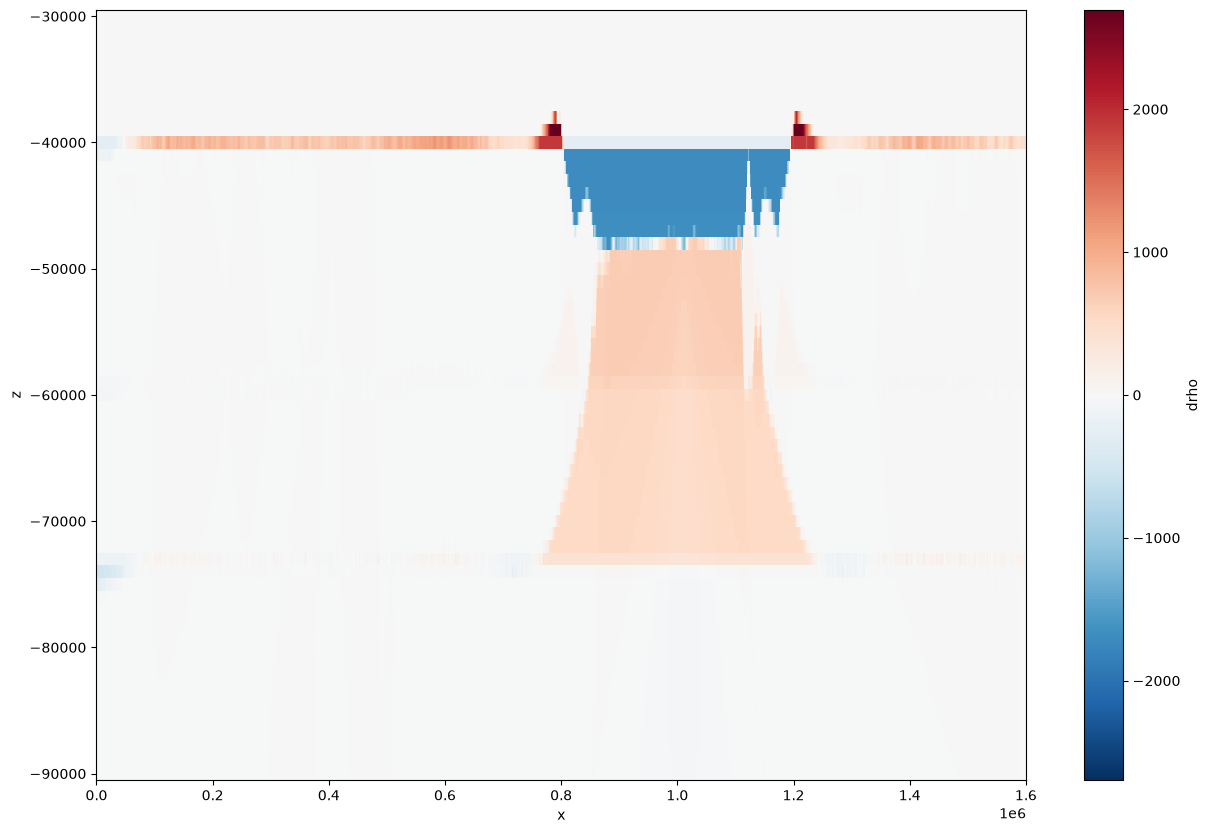

In [5]:
drho.sel(z=slice(-90e3, -30e3)).plot(figsize=(15, 10))

#With the reference in the first time step, there was a positive band in the far field at about -75 km. It is at the depth of the
#Moho (-75 km in interfaces.txt), not at the base of the lithosphere: the Moho rises about 1.6 km. Leo said that this may be a problem.
#The reference in the same time step removes this band from the contrast, but the cause of this rise was not investigated.

## 4. Forward modelling

**From 2D to 3D.** The model is 2D, so the prisms are long in the northing direction. `half_y` of $10^7$ m and $10^9$ m differ by only 0.02 mGal, and here `half_y` is $3.2 \times 10^7$ m.

**Observation level.** Decided with Leonardo Uieda: a flat level, the same in all the time steps, `obs_height` (1 km) above the highest surface of the whole simulation. No rock is above the observation level, and the height does not change with `x` or with time, so the profiles can be compared between time steps.

Levels that followed the surface had points above and below the rock of the reference (+421 mGal in the ocean of `compression_left_dec`) and inside the mean density of the cell with the surface (about 150 mGal with cells of 2 km).

**Consequence.** The level depends on each scenario, and it is farther from the sources where the topography is low, which smooths and reduces their anomalies. So compare with data at the same height, not directly with surface free-air anomalies. If `obs_height` is smaller than `dz`, the level can be inside the cell of the highest surface. The profile is not filtered to the resolution of the data here.

In [6]:
half_y = x[-1] * 20.0 #half length of the domain in y-direction (northing) and should be 20 times the x-length

#creating prisms
prisms = np.column_stack([
                        X.ravel() - dx / 2, #Return a contiguous flattened array.
                        X.ravel() + dx / 2,
                        np.full(X.size, -half_y), #northing
                        np.full(X.size, half_y), #northing
                        Z.ravel() - dz / 2,
                        Z.ravel() + dz / 2,                        
                        ])

#The columns at the sides extend the model in x
prisms_left = np.column_stack([np.full(Nz, x[0] - dx/2 - half_y), np.full(Nz, x[0] - dx/2), np.full(Nz, -half_y), np.full(Nz, half_y), z_bottom, z_top])
prisms_right = np.column_stack([np.full(Nz, x[-1] + dx/2), np.full(Nz, x[-1] + dx/2 + half_y), np.full(Nz, -half_y), np.full(Nz, half_y), z_bottom, z_top])
prisms = np.vstack([prisms, prisms_left, prisms_right])

density = np.concatenate([drho.values.ravel(), drho.values[:, 0], drho.values[:, -1]])

topography = topo_t
x_aux = np.linspace(0, x[-1], len(topography))

#Observation level above all the surfaces of the simulation
highest_surface = max(float(surface.max()), sea_level)
z_obs = highest_surface + obs_height
coords = (x, np.zeros_like(x), np.full_like(x, z_obs))
print(f"Highest surface: {highest_surface} m. z_obs: {z_obs} m")

ge = hm.prism_gravity(coords, prisms, density, field="g_e") #eating component of gravity
gn = hm.prism_gravity(coords, prisms, density, field="g_n") #northing component of gravity
gz = hm.prism_gravity(coords, prisms, density, field="g_z") #downward component of gravity
gz = gz - gz[far_columns].mean() #the far field is the zero of g_z
potential = hm.prism_gravity(coords, prisms, density, field="potential")

Highest surface: -37110.8984375 m. z_obs: -36110.8984375 m


/var/folders/ss/gq1wd5111xj_bmqvllgj5zdw0000gn/T/ipykernel_92343/3624965930.py:32: RuntimeWarning: divide by zero encountered in log10
  ax3.imshow(np.log10(np.where(air, 0.0, strain_t)[::-1, :]), extent=(0, Lx/1000, Lz/1000+40, 40), cmap="Greys", vmin=-0.5, vmax=0.9, alpha=0.2, aspect='auto')


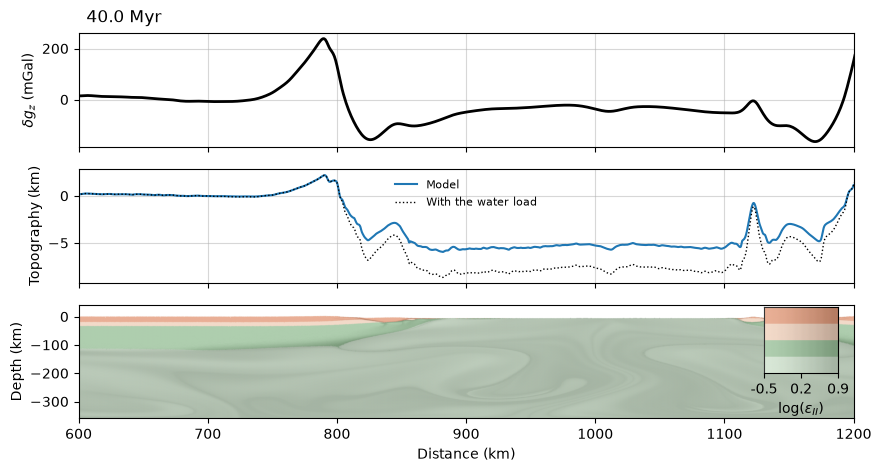

In [7]:
h_air = 40.0e3 #m

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
ax1.plot(x / 1.0e3, gz, color='k', lw=2)
ax2.plot(x_aux / 1.0e3, (topography + h_air) / 1e3, label='Model')
if(water):
    ax2.plot(x / 1.0e3, (surface_sunk + h_air) / 1e3, color='k', lw=1, ls=':', label='With the water load')
    ax2.legend(loc='upper center', fontsize=8, frameon=False)


ax1.text(0.01, 1.1, f"{t:.1f} Myr", transform=ax1.transAxes, fontsize=12, color='k')

ax1.set_ylabel(r"$\delta g_z$ (mGal)")
ax2.set_ylabel("Topography (km)")
ax3.set_ylabel('Depth (km)')
ax3.set_xlabel("Distance (km)")

# ax1.set_xlim(0, x[-1] / 1000)
ax1.set_xlim(600, 1200)


ax1.grid('-k', alpha=0.5)
ax2.grid('-k', alpha=0.5)

lithology_colors = 'auto'
colors = get_lithology_colors(model_path, lithology_colors)
cmap = ListedColormap(colors)

air = rho_t < 1200.0 #tapioca keeps the values in the air: set them to zero there

ax3.imshow(litho_t[::-1, :], aspect='auto', extent=(0, Lx/1000, Lz/1000+40, 40), cmap=cmap, vmin=-0.5, vmax=len(colors)-0.5, alpha=1.0)
ax3.imshow(np.log10(np.where(air, 0.0, strain_t)[::-1, :]), extent=(0, Lx/1000, Lz/1000+40, 40), cmap="Greys", vmin=-0.5, vmax=0.9, alpha=0.2, aspect='auto')

cr = 255.
color_air = (1.,1.,1.) # 5
color_bas = 'xkcd:dark grey blue' #(250./cr,50./cr,50./cr) # 4
color_uc = (228./cr,156./cr,124./cr) # 3
color_lc = (240./cr,209./cr,188./cr) # 2
color_lit = (155./cr,194./cr,155./cr) # 1
color_ast = (207./cr,226./cr,205./cr) # 0
bv1 = plot_lithology_legend(ax3, colors=[color_uc, color_lc, color_lit, color_ast], vmin=-0.5, vmax=0.9, alpha=0.2,
                                        position=(0.98, 0.4), loc='lower right')

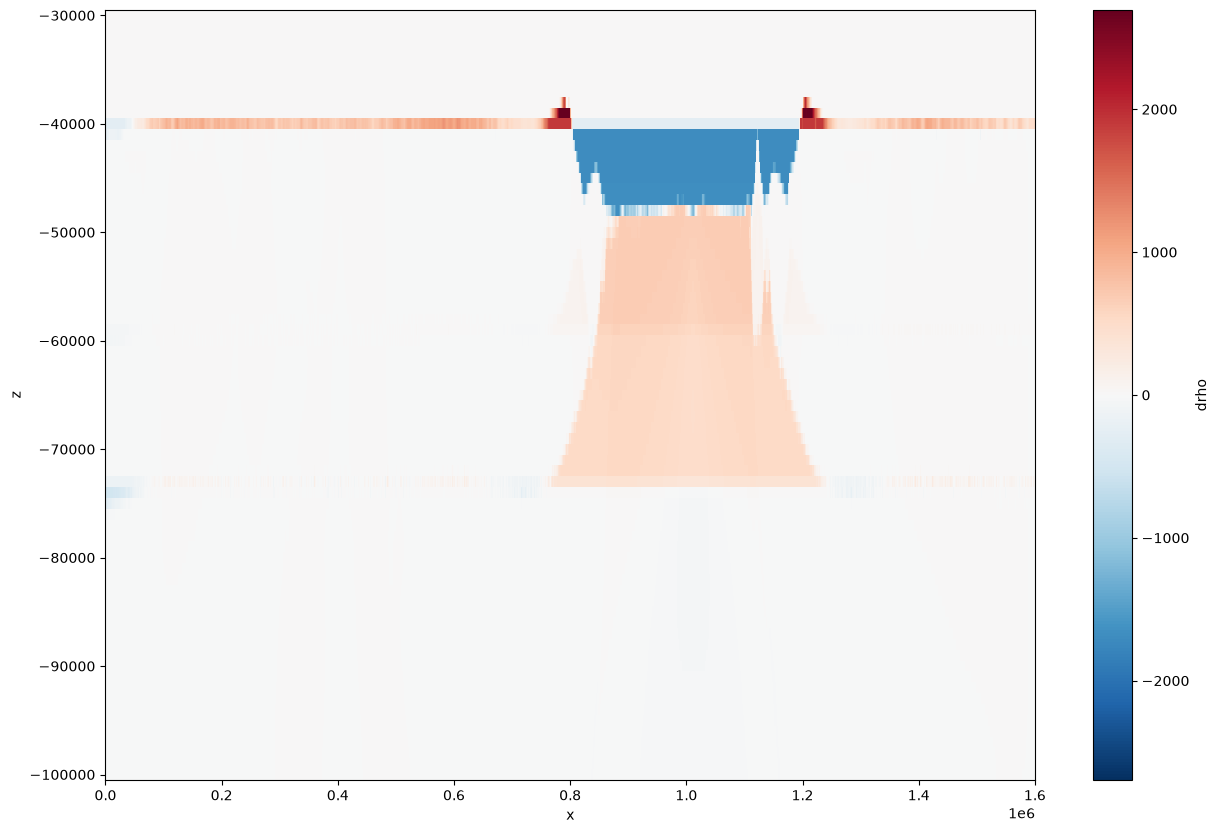

In [8]:
drho.sel(z=slice(-100.e3, -30.e3)).plot(figsize=(15, 10))

## 5. What is not included

Sediments, surface processes and flexure are not included. The peaks at the margins are still high.

We tested these effects after the simulation, at 20, 40 and 60 Myr, always with water. This test had points following the surface and a far field chosen by hand, so it shows the relative effects, not the current values:

| Test | Peak (mGal) | Minimum (mGal) |
|---|---|---|
| Base | 242–304 | −160 to −171 |
| Without the rock above the sea level, no rebound | 92–127 | −156 to −169 |
| Eroded to the sea level, with isostatic rebound | 150–158 | −145 to −153 |
| Same, with a sediment wedge (5 km, L = 150 km) | 136–145 | −136 to −143 |
| Scarp kept, with a sediment wedge (2–8 km) | 225–300 | −139 to −169 |

So most of the difference in the peaks comes from the scarp, as expected for a scenario without surface processes. The sediments change the peaks by about 20 mGal or less in this test, in which the Airy isostasy keeps the mass of each column. Peaks of about 150 mGal and minimums of about −140 mGal remain.

These tests only bound the effect. They do not replace a simulation with surface processes, which would also change the evolution of the rift. Removing the rock without rebound takes mass out of the columns. The erosion with rebound needs 13–16 km of erosion, which is too much, and it does not fully keep the mass of the columns.